# Project 2: Sentiment analysis & Topic modelling

### Part 1: Sentiment analysis (IMDb reviews)

1. Clean the text 
2. Split 80% train / 20% validation before building vocab, to prevent data leakage
3. Convert reviews to fixed-length sequences of word indices
4. Model: Embedding (100-dim) → average of word vectors → Linear + ReLU + Dropout → Linear + Sigmoid
5. Train while monitoring the val loss each epoch, keep the best epoch 

In [1]:
import re, random, copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, classification_report, confusion_matrix

# Reproducibility
SEED = 42
random.seed(SEED); 
np.random.seed(SEED); 
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#### 1.1 Load, clean and split the data

In [3]:
df = pd.read_csv('Data/IMDB Dataset.csv')
print(df.shape)
# check that classes are balanced
print(df['sentiment'].value_counts())   

# positive -> 1, negative -> 0
df['label'] = (df['sentiment'].str.lower() == 'positive').astype(int)

def clean_text(text):
    text = str(text).lower()
    # remove HTML tags like <br />
    text = re.sub(r'<.*?>', ' ', text)  
    # remove punctuation
    text = re.sub(r'[^\w\s]', '', text)     
    return text

df['clean_review'] = df['review'].apply(clean_text)

# 80/20 train-validation split
train_texts, val_texts, train_labels, val_labels = train_test_split(df['clean_review'].values, df['label'].values,test_size=0.2, random_state=SEED)
print(f"Train: {len(train_texts)} reviews | Validation: {len(val_texts)} reviews")

(50000, 2)
sentiment
positive    25000
negative    25000
Name: count, dtype: int64
Train: 40000 reviews | Validation: 10000 reviews


#### 1.2 Vocabulary and tokenisation
* vocabulary built on the training set
* keep the 10,000 most frequent words
* pad or truncate reviews to 200 words so all input has the same length

In [4]:
MAX_VOCAB_SIZE = 10000
MAX_LEN = 200

word_counts = Counter()
for text in train_texts:
    word_counts.update(text.split())

vocab = ['<PAD>', '<UNK>'] + [w for w, _ in word_counts.most_common(MAX_VOCAB_SIZE - 2)]
word2idx = {w: i for i, w in enumerate(vocab)}

def text_to_indices(text, max_len=MAX_LEN):
    idx = [word2idx.get(tok, word2idx['<UNK>']) for tok in text.split()][:max_len]
    return idx + [word2idx['<PAD>']] * (max_len - len(idx))

X_train = np.array([text_to_indices(t) for t in train_texts])
X_val   = np.array([text_to_indices(t) for t in val_texts])

class IMDbDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):return len(self.X)
    def __getitem__(self, i):return self.X[i], self.y[i]

train_loader = DataLoader(IMDbDataset(X_train, train_labels), batch_size=64, shuffle=True)
val_loader   = DataLoader(IMDbDataset(X_val, val_labels), batch_size=64, shuffle=False)

#### 1.3 Feedforward neural network
* embeddings (dimension 100) are learned from scratch 
* review is represented by the avg of its word vectors, where padding positions are ignored 
* short and long reviews are treated fairly and the vector then goes through 1 hidden layer

In [5]:
class SentimentFFN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=100, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # (batch, seq_len, 100)
        emb = self.embedding(x)     
        # 1 for real words, 0 for padding
        mask = (x != 0).unsqueeze(-1).float()           
        # average over real words
        pooled = (emb * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)   
        out = self.dropout(self.relu(self.fc1(pooled)))
        return self.sigmoid(self.fc2(out)).squeeze(1)

model = SentimentFFN(len(vocab), embedding_dim=100, hidden_dim=128).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(model)

SentimentFFN(
  (embedding): Embedding(10000, 100, padding_idx=0)
  (fc1): Linear(in_features=100, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


#### 1.4 Training
* evaluate on the val set after every epoch
* training loss that falls while val loss rises is a sign of overfitting
* so we keep the weights from the epoch with the lowest val loss

In [6]:
def evaluate(loader):
    model.eval()
    total_loss, preds, targets = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * len(y)
            preds.extend((out >= 0.5).float().cpu().numpy())
            targets.extend(y.cpu().numpy())
    return total_loss / len(loader.dataset), np.array(preds), np.array(targets)

EPOCHS = 10
history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
best_val_loss, best_state, best_epoch = float('inf'), None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(y)
    train_loss = running / len(train_loader.dataset)

    val_loss, val_preds, val_true = evaluate(val_loader)
    val_acc = accuracy_score(val_true, val_preds)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)
print(f"\nBest epoch: {best_epoch}")

Epoch  1/10 | train loss 0.4922 | val loss 0.3566 | val acc 0.8438
Epoch  2/10 | train loss 0.3165 | val loss 0.3103 | val acc 0.8649
Epoch  3/10 | train loss 0.2659 | val loss 0.2992 | val acc 0.8708
Epoch  4/10 | train loss 0.2365 | val loss 0.3010 | val acc 0.8722
Epoch  5/10 | train loss 0.2142 | val loss 0.3052 | val acc 0.8713
Epoch  6/10 | train loss 0.1982 | val loss 0.3205 | val acc 0.8709
Epoch  7/10 | train loss 0.1857 | val loss 0.3278 | val acc 0.8704
Epoch  8/10 | train loss 0.1743 | val loss 0.3384 | val acc 0.8697
Epoch  9/10 | train loss 0.1657 | val loss 0.3546 | val acc 0.8647
Epoch 10/10 | train loss 0.1564 | val loss 0.3633 | val acc 0.8644

Best epoch: 3


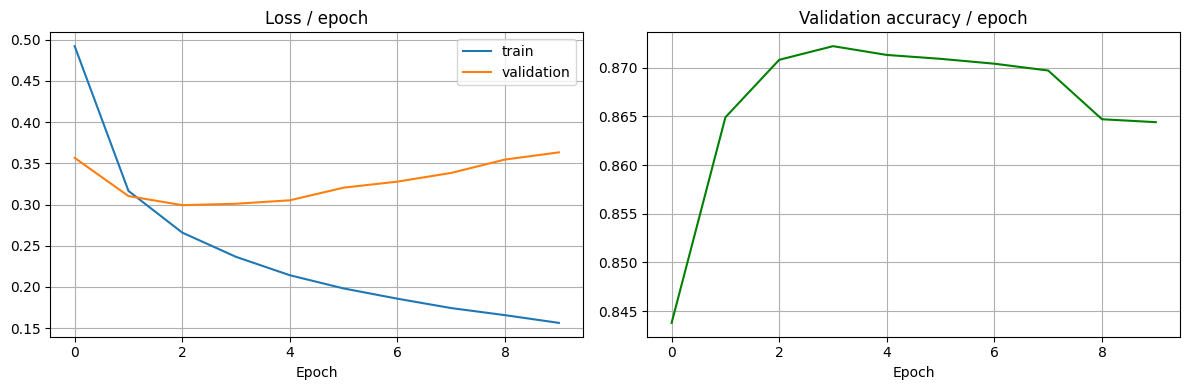

In [7]:
# Learning curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='validation')
ax[0].set_title('Loss / epoch'); ax[0].set_xlabel('Epoch'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(history['val_acc'], color='green')
ax[1].set_title('Validation accuracy / epoch'); ax[1].set_xlabel('Epoch'); ax[1].grid(True)
plt.tight_layout(); plt.show()

#### 1.5 Evaluation on the validation set 

In [8]:
_, val_preds, val_true = evaluate(val_loader)

precision, recall, f1, _ = precision_recall_fscore_support(val_true, val_preds, average='binary')
print("Validation results")
print(f"Accuracy  : {accuracy_score(val_true, val_preds):.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}\n")

print(classification_report(val_true, val_preds, target_names=['negative', 'positive'], digits=4))

cm = confusion_matrix(val_true, val_preds)
print("Confusion matrix")
print(cm)

Validation results
Accuracy  : 0.8708
Precision : 0.8703
Recall    : 0.8738
F1-score  : 0.8721

              precision    recall  f1-score   support

    negative     0.8713    0.8678    0.8695      4961
    positive     0.8703    0.8738    0.8721      5039

    accuracy                         0.8708     10000
   macro avg     0.8708    0.8708    0.8708     10000
weighted avg     0.8708    0.8708    0.8708     10000

Confusion matrix
[[4305  656]
 [ 636 4403]]


**model** A feedforward network with a 100-dimensional embedding learned from scratch, a masked average over the words of a review, one hidden layer (128 units, ReLU, dropout 0.5) and a sigmoid output. It was trained on a random 80% of the reviews (40,000) and evaluated on the remaining 20%. The vocabulary (10,000 words) was built on the training set only and reviews were padded or truncated to 200 words

**performance** Accuracy 0.8708, precision 0.8703, recall 0.8738, F1-score 0.8721

| Class | Precision | Recall | F1-score |
|---|---|---|---|
| negative | 0.8713 | 0.8678 | 0.8695 |
| positive | 0.8703 | 0.8738 | 0.8721 |

- network classifies about 87% of unseen reviews correctly
- Precision, recall and F1 are almost identical, so the model is well balanced and the F1-scores differ by only 0.003
- 656 negative reviews were predicted as positive (false positives) and 636 positive reviews as negative (false negatives)
- 1,292 errors (12.9%) are spread almost evenly over the two types -> dataset is balanced and the random split kept the classes close to 50/50
- **Overfitting:** training loss falls from 0.492 to 0.156 over 10 epochs, but val loss reaches its minimum (0.299) at **epoch 3** and then rises
- validation accuracy peaks at 0.872 (epoch 4) and drifts down to 0.864.
- restore the epoch-3 weights (lowest validation loss), which gives the reported 0.8708 accuracy
- The x-axis of the learning-curve plot starts at 0, so "2" corresponds to epoch 3 in log
- validation set was used both to choose the best epoch and to report final scores, so the 87% is slightly optimistic
- **Limitations:** averaging word vectors discards word order, so negation ("not good"), sarcasm and mixed reviews are hard to capture, and reviews were truncated to 200 words, so sentiment expressed late in a long review is lost
- **Possible improvements:** pretrained embeddings, a recurrent, convolutional or transformer model, or stronger regularisation.

---
### Topic modelling (ABC news headlines)

1. Load headlines and parse dates. Use a random sample of 500,000 headlines for both methods so the results are comparable (full corpus over 1 mil)
2. Remove English stop words plus a few uninformative words 
3. **LSA**: TF-IDF followed by truncated SVD - **LDA**: word counts followed by Latent Dirichlet Allocation
4. Describe each topic by its most important words
5. Track how LDA topics evolve per year

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation

SEED = 42
NUM_TOPICS = 8     

#### 2.1 Load and prepare the data

In [ ]:
df_news = pd.read_csv('abcnews-date-text.csv')
df_news['publish_date'] = pd.to_datetime(df_news['publish_date'], format='%Y%m%d', errors='coerce')
df_news = df_news.dropna(subset=['publish_date', 'headline_text'])
print("Total headlines:", len(df_news))
print("Date range:", df_news['publish_date'].min().date(), "to", df_news['publish_date'].max().date())

# One shared sample for LSA and LDA 
df_sample = df_news.sample(n=min(500_000, len(df_news)), random_state=SEED).reset_index(drop=True)
df_sample['year'] = df_sample['publish_date'].dt.year
headlines_sample = df_sample['headline_text'].values

# English stop words + common, uninformative headline words
custom_stop_words = list(ENGLISH_STOP_WORDS) + ['interview', 'says', 'say', 'abc', 'news', 'new']

df_sample.head()

Total headlines: 1244184
Date range: 2003-02-19 to 2021-12-31


,publish_date,headline_text,year
0,2018-10-17,virtual reality trial ahead of fire season in ...,2018
1,2007-01-31,farmers prepare for ec funding,2007
2,2014-08-10,the sunday inquisition august 10,2014
3,2013-02-21,news csg reax,2013
4,2014-08-06,rosetta spacecraft on final approach to comet ...,2014


In [ ]:
# top words of each topic
def get_top_words(model, feature_names, n_top_words=10):
    topics = []
    for topic in model.components_:
        top_idx = topic.argsort()[:-n_top_words - 1:-1]
        topics.append([feature_names[i] for i in top_idx])
    return topics

def print_topics(topics):
    for i, words in enumerate(topics, start=1): print(f"Topic #{i}: {', '.join(words)}")

#### Choosing the number of topics (topic coherence)
- The number of topics K has to be chosen by us, so we compare LDA models for K = 2, 4, …, 30 by **topic coherence**: do the top-10 words of a topic actually appear together in the same headlines?
- **UMass coherence**: for each pair of top words, log((D(wᵢ, wⱼ) + 1) / D(wⱼ)), with D the number of headlines containing the word(s). Closer to 0 is better.
- **NPMI coherence**: normalised pointwise mutual information of each word pair, between −1 (never together) and 1 (always together). Higher is better. Headlines are very short, so many word pairs never co-occur and values are negative.
- Both are averaged over all word pairs and all topics. To keep the run time manageable, the models are fitted on a random subsample of 100,000 headlines (≈2 minutes per K).

In [ ]:
# Topic coherence for K = 2, 4, ..., 30 This code was generated with the help of Claude Code
coh_sub = pd.Series(headlines_sample).sample(n=100_000, random_state=SEED).values
coh_cv = CountVectorizer(max_features=5000, min_df=5, stop_words=custom_stop_words)
coh_X = coh_cv.fit_transform(coh_sub)

B = (coh_X > 0).astype(np.float64).tocsc()  # headline x word: does the word occur? 0 if not occur 1 if occur
n_docs = B.shape[0]
doc_freq = np.asarray(B.sum(axis=0)).ravel()  # D(w): number of headlines with word w


def coherence(model, top_n=10):
    umass, npmi = [], []
    for comp in model.components_:
        top = comp.argsort()[::-1][:top_n]
        co = (B[:, top].T @ B[:, top]).toarray()  # D(wi, wj): headlines with both words
        u, v = [], []
        for i in range(1, top_n):
            for j in range(i):
                u.append(np.log((co[i, j] + 1) / doc_freq[top[j]]))
                p_ij = co[i, j] / n_docs
                p_i, p_j = doc_freq[top[i]] / n_docs, doc_freq[top[j]] / n_docs
                v.append(-1.0 if p_ij == 0 else np.log(p_ij / (p_i * p_j)) / -np.log(p_ij))
        umass.append(np.mean(u))
        npmi.append(np.mean(v))
    return np.mean(umass), np.mean(npmi)


K_values = list(range(6, 31, 3))
rows = []
for k in K_values:
    m = LatentDirichletAllocation(n_components=k, learning_method="online", batch_size=2048,
                                  max_iter=10, random_state=SEED, n_jobs=-1).fit(coh_X)
    u, v = coherence(m)
    rows.append((k, u, v))
    print(f"K={k:2d}  UMass={u:.3f}  NPMI={v:.4f}")
coh_df = pd.DataFrame(rows, columns=["K", "UMass", "NPMI"]).set_index("K")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, col in zip(ax, ["UMass", "NPMI"]):
    a.plot(coh_df.index, coh_df[col], "o-")
    a.axvline(NUM_TOPICS, color="grey", ls=":", label=f"K = {NUM_TOPICS} (used)")
    a.set_xlabel("number of topics K")
    a.set_ylabel(f"{col} coherence (higher = better)")
    a.set_title(f"{col} coherence vs K")
    a.set_xticks(K_values)
    a.grid(True)
    a.legend()
plt.tight_layout()
plt.show()

#### 2.2 Latent Semantic Analysis (LSA)
- apply truncated SVD to the TF-IDF matrix and each component is a topic described by the words with the highest weights
- Components can be negative and are not probabilities, so are harder to interpret 

In [ ]:
tfidf_vectorizer = TfidfVectorizer(max_features=5000, min_df=5, stop_words=custom_stop_words)
tfidf_matrix = tfidf_vectorizer.fit_transform(headlines_sample)

lsa_model = TruncatedSVD(n_components=NUM_TOPICS, random_state=SEED)
lsa_matrix = lsa_model.fit_transform(tfidf_matrix)

print("LSA topics (top 10 words)")
lsa_topics = get_top_words(lsa_model, tfidf_vectorizer.get_feature_names_out(), 10)
print_topics(lsa_topics)
print("\nExplained variance per component:", np.round(lsa_model.explained_variance_ratio_, 4))

LSA topics (top 10 words)
Topic #1: police, man, charged, court, murder, crash, missing, car, death, woman
Topic #2: police, investigate, probe, nsw, search, hunt, officer, seek, wa, arrest
Topic #3: govt, nsw, council, rural, australia, water, health, plan, national, wa
Topic #4: rural, national, nsw, man, charged, sa, dies, qld, reporter, country
Topic #5: court, rural, national, murder, accused, face, nsw, charges, faces, told
Topic #6: australia, day, rural, national, world, murder, cup, nsw, south, court
Topic #7: crash, car, dies, killed, court, fatal, woman, road, driver, plane
Topic #8: council, australia, rural, national, death, plan, crash, charged, wins, weather

Explained variance per component: [0.0032 0.003  0.0017 0.0021 0.002  0.002  0.0019 0.0018]


#### 2.3 Latent Dirichlet Allocation (LDA)
each headline is a mixture of topics, and each topic is a probability distribution over words using raw word counts (not TF-IDF)

In [ ]:
count_vectorizer = CountVectorizer(max_features=5000, min_df=5, stop_words=custom_stop_words)
count_matrix = count_vectorizer.fit_transform(headlines_sample)

lda_model = LatentDirichletAllocation(n_components=NUM_TOPICS,learning_method='online',batch_size=2048,max_iter=10,random_state=SEED,n_jobs=-1)
lda_matrix = lda_model.fit_transform(count_matrix)
lda_matrix = lda_matrix / lda_matrix.sum(axis=1, keepdims=True)   # each row = topic probabilities of one headline

print("LDA topics")
lda_topics = get_top_words(lda_model, count_vectorizer.get_feature_names_out(), 10)
print_topics(lda_topics)

LDA topics
Topic #1: crash, council, car, plan, funding, boost, water, fears, road, gets
Topic #2: australia, day, coronavirus, win, test, years, killed, return, end, victoria
Topic #3: police, man, charged, woman, home, gold, dead, dies, death, attack
Topic #4: report, world, cup, final, country, jailed, public, health, indigenous, live
Topic #5: rural, hospital, nt, year, national, ban, change, state, sa, funds
Topic #6: open, fight, australian, trump, lead, continues, industry, storm, union, nrl
Topic #7: court, north, face, south, man, market, trial, murder, charges, accused
Topic #8: missing, minister, labor, budget, govt, search, wa, election, defends, business


#### Characterisation of the topics

The top-10 words are the most characteristic words of each topic (for LSA the largest loadings, for LDA the highest topic–word weights). 
- Short headlines and only 8 topics mean that some topics mix several themes.

**LSA topics**

| Topic | Top words (abridged) | Interpretation |
|---|---|---|
| 1 | police, man, charged, court, murder, crash, missing, car, death, woman | General **crime, police and accidents**: the strongest overall pattern in the data |
| 2 | police, investigate, probe, nsw, search, hunt, officer, seek, wa, arrest | **Police investigations and manhunts** (searching, probing, arrests) |
| 3 | govt, nsw, council, rural, australia, water, health, plan, national, wa | **Government, local councils and public services** (water, health, planning) |
| 4 | rural, national, nsw, man, charged, sa, dies, qld, reporter, country | **Regional and state news** (state abbreviations; "rural"/"national" look like ABC programme labels) |
| 5 | court, rural, national, murder, accused, face, nsw, charges, faces, told | **Courts, trials and charges** |
| 6 | australia, day, rural, national, world, murder, cup, nsw, south, court | Mixed: **national/world events and sport** ("world cup") |
| 7 | crash, car, dies, killed, court, fatal, woman, road, driver, plane | **Road and transport accidents** (fatal crashes) |
| 8 | council, australia, rural, national, death, plan, crash, charged, wins, weather | Mixed: council/planning, crashes, weather |

- LSA topics **overlap strongly**: the same words (police, murder, court, rural, national, nsw, charged) recur in several topics, which is typical as each component must be orthogonal to the previous ones and the first components pick up the biggest sources of variance (crime/police news)
- **explained variance is very small** (0.17%–0.32% per component, only about 1.6% for the 8 components together)- normal for sparse TF-IDF on very short texts, where every headline uses only a handful of the 5,000 words
  
**LDA topics**

| Topic | Top words (abridged) | Interpretation |
|---|---|---|
| T1 | crash, council, car, plan, funding, boost, water, fears, road, gets | **Local infrastructure and council news**: roads, funding, water, planning |
| T2 | australia, day, coronavirus, win, test, years, killed, return, end, victoria | **National news, sport results and COVID-19** (mixed; the "coronavirus" keyword is the key feature) |
| T3 | police, man, charged, woman, home, gold, dead, dies, death, attack | **Crime and police incidents** (arrests, attacks, deaths; "gold" probably refers to the Gold Coast) |
| T4 | report, world, cup, final, country, jailed, public, health, indigenous, live | **Reports and world/sport events** (world cup, finals, live coverage) mixed with public health and Indigenous affairs |
| T5 | rural, hospital, nt, year, national, ban, change, state, sa, funds | **Regional and state health/policy** (hospitals, funding, bans, state names) |
| T6 | open, fight, australian, trump, lead, continues, industry, storm, union, nrl | **Sport, industry and international politics** (Australian Open, NRL, unions, Trump, storms): the most mixed topic |
| T7 | court, north, face, south, man, market, trial, murder, charges, accused | **Courts and criminal trials** |
| T8 | missing, minister, labor, budget, govt, search, wa, election, defends, business | **Politics, government and elections** (ministers, budget, Labor), with "missing/search" mixed in |

**LSA vs LDA**
- crime and police (LSA 1, 2; LDA T3), courts and trials (LSA 5; LDA T7), road crashes/transport (LSA 7; LDA T1), and government, councils and regional/state news (LSA 3, 4; LDA T1, T5, T8) were highlighted by both
- LSA spreads the crime/court theme over four or five components, while LDA assigns it to two separate topics (police incidents vs. courts) and leaves room for politics (T8), sport and international news (T4, T6) and COVID-19 (T2)
- LSA topics are harder to label because the later components mix many themes

#### 2.4 Evolution of the topics through time
* For every headline, LDA gives a probability for each topic
* take the average topic probability per year, which shows how much of the news each topic represents in that year
* Years with far fewer headlines than usual (below 40% of the median) are dropped-> this removes 2021
* LSA is not used as its components are not probabilities and can be negative, so a "share per year" has no meaning

In [ ]:
topic_labels = [f"T{i+1}: " + ", ".join(words[:3]) for i, words in enumerate(lda_topics)]

# Number of sampled headlines per year 
year_counts = df_sample['year'].value_counts().sort_index()
print(year_counts.to_string())

# Drop years with much less data than usual 
valid_years = year_counts[year_counts >= 0.4 * year_counts.median()].index

topic_year = (pd.DataFrame(lda_matrix, columns=topic_labels).groupby(df_sample['year']).mean().loc[valid_years])
topic_year.round(3).head()

year
2003    25528
2004    29036
2005    29545
2006    26804
2007    30952
2008    32472
2009    30559
2010    30241
2011    31283
2012    35726
2013    36898
2014    32544
2015    31023
2016    24755
2017    19122
2018    16209
2019    13857
2020    16224
2021     7222


,"T1: crash, council, car","T2: australia, day, coronavirus","T3: police, man, charged","T4: report, world, cup","T5: rural, hospital, nt","T6: open, fight, australian","T7: court, north, face","T8: missing, minister, labor"
year,,,,,,,,
2003,0.144,0.113,0.134,0.112,0.124,0.116,0.131,0.127
2004,0.148,0.109,0.131,0.109,0.126,0.113,0.135,0.127
2005,0.148,0.107,0.129,0.107,0.126,0.114,0.140,0.129
2006,0.149,0.110,0.129,0.111,0.124,0.112,0.137,0.127
2007,0.145,0.109,0.133,0.108,0.126,0.112,0.136,0.130


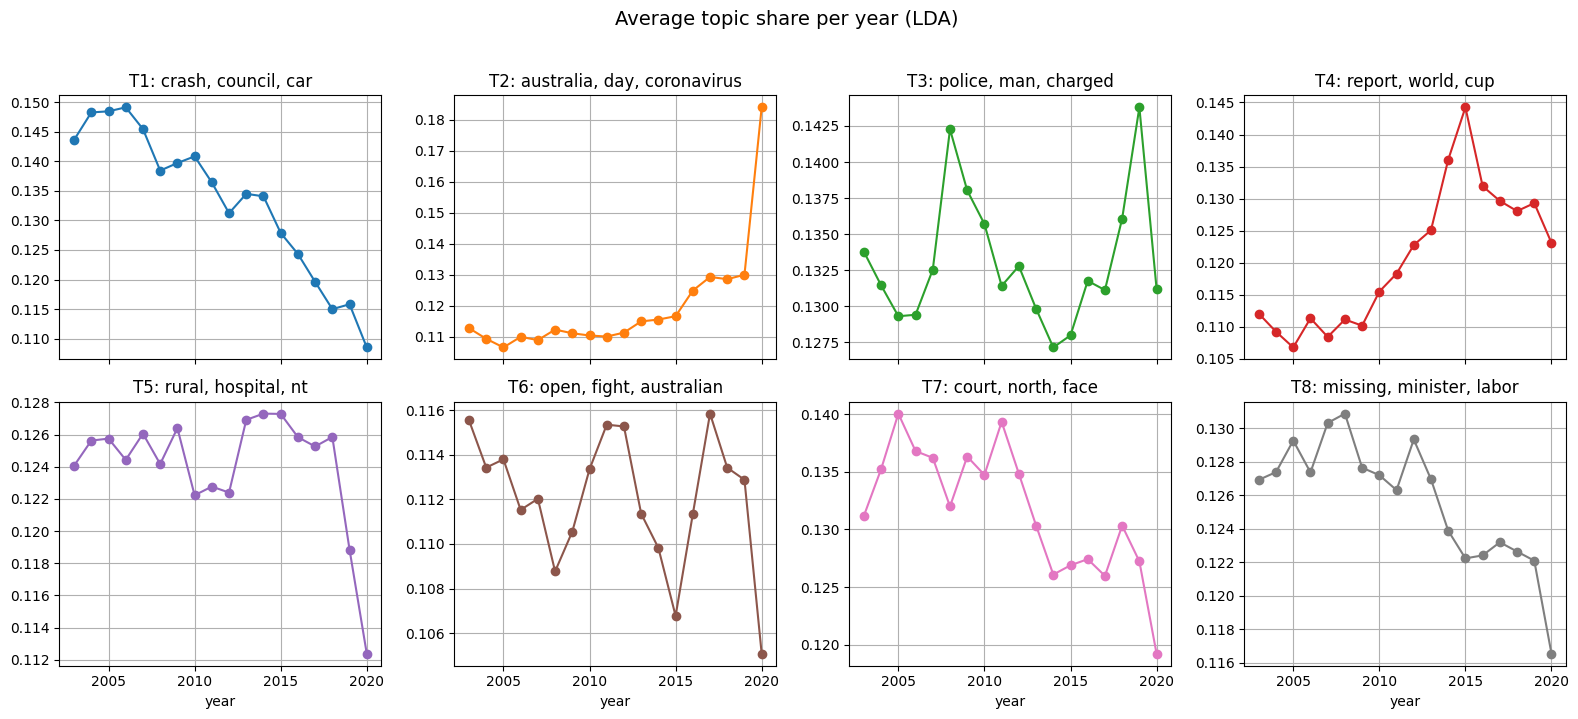

In [ ]:
# One plot per topic 
n_cols = 4
n_rows = int(np.ceil(NUM_TOPICS / n_cols))
axes = topic_year.plot(subplots=True, layout=(n_rows, n_cols), figsize=(16, 3.5 * n_rows),sharex=True, sharey=False, legend=False, marker='o', grid=True,title=list(topic_year.columns))
plt.suptitle('Average topic share per year (LDA)', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

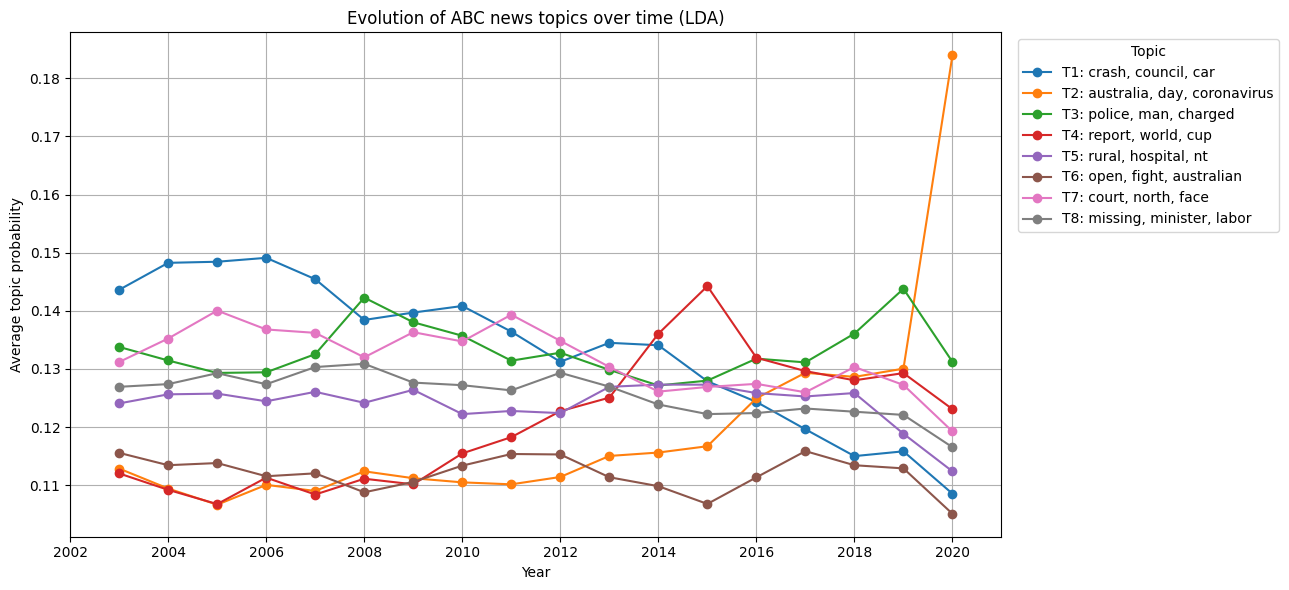

In [ ]:
# all topics in one chart
from matplotlib.ticker import MaxNLocator
ax = topic_year.plot(figsize=(13, 6), marker='o')
ax.set_title('Evolution of ABC news topics over time (LDA)')
ax.set_xlabel('Year'); 
ax.set_ylabel('Average topic probability')
ax.grid(True)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(2002,2021)
ax.legend(title='Topic', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); 
plt.show()

#### Evolution of the topics 

Most topics change only gradually between 2003 and 2020. 
- Crash/council news (T1), courts (T7) and politics/government (T8) lose share
- reports/world/sport (T4) rises to a peak around 2015 and then falls back
- crime reporting (T3) stays roughly constant
- clearest change is the jump of the coronavirus-related topic (T2) in 2020.

**plots** each line is the average LDA topic probability per year. With 8 topics, an even split would be 0.125. All topic shares sum to 1, so when one topic grows, others must shrink. Most year-to-year changes are small (1–3 percentage points)

**Topics that grow**
- **T2 (australia, day, coronavirus):** flat from 2003 to 2012, rises slowly from 2013 (~0.115 to ~0.130 in 2019), then jumps to ~0.184 in 2020. This matches the COVID-19 pandemic. The jump comes at the expense of the other topics: all seven of them fall in 2020. T2 is a mixed topic (it also contains win, test, day, years), so the COVID reading rests mainly on the keyword "coronavirus".
- **T4 (report, world, cup):** increases from a low of ~0.107 (2005) to a peak of ~0.144 in 2015, then falls back to ~0.123 in 2020. The 2015 peak may be linked to sporting events held in Australia that year (the AFC Asian Cup, won by Australia for the first time, and the Cricket World Cup). T4 also contains reports, public health and Indigenous affairs, so the trend is not necessarily sport only. 

**Topics that decline**
- **T1 (crash, council, car):** a steady decline from ~0.149 (2006) to ~0.109 (2020), the largest long-term decrease (about 4 points).
- **T7 (court, north, face):** highest around 2005 (~0.140) and 2011 (~0.139), then falls to ~0.126 by 2014 and ~0.119 in 2020, so court and trial headlines become less common.
- **T8 (missing, minister, labor):** highest in 2003–2008 (up to ~0.131), a small bump in 2012, then declines to ~0.122 by 2015 and ~0.117 in 2020. Political and government headlines occupy a smaller part of the news mix in later years.

**Stable or fluctuating topics**
- **T3 (police, man, charged):** fluctuates between ~0.127 and ~0.144, with peaks in 2008 (~0.142) and 2019 (~0.144) and a low in 2014. It falls back to ~0.131 in 2020. Crime reporting is a constant part of ABC news, with fluctuations of 1–2 points and no long-term trend.
- **T5 (rural, hospital, nt):** stable around 0.122–0.127 until 2018, then declines to ~0.119 (2019) and ~0.112 (2020). The decline starts before COVID-19, so only part of the 2020 fall may reflect T2 taking up more space.
- **T6 (open, fight, australian):** zig-zags between 0.105 and 0.116 with no trend. This fits event-driven coverage (sport tournaments, elections, news about the US president; the 2017 peak coincides with the start of Trump's presidency).

**Caveats**
- 2021 is excluded because the sample has only 7,222 headlines for it, against a median of about 29,500 per year. The headline count also falls from ~36,900 (2013) to ~16,000 (2018, 2020), so the later yearly averages are somewhat noisier.
- Results are based on a random sample of 500,000 headlines, 8 topics and one LDA run

**Overall.** ABC headlines are made up of a few recurring themes- crime and courts, local government and infrastructure, regional news and health, politics, and sport/world events. Over the 18 analysed years the mix changes only gradually. Crime reporting (T3) fluctuates around 13–14% with no long-term trend, while local infrastructure/crash news (T1), courts (T7) and political headlines (T8) lose some share. International/sport coverage (T4) rises to a peak around 2015. The most striking change is the 2020 jump of the coronavirus-related topic (T2), which reflects how strongly the pandemic dominated the news.